# Olist E-Commerce: Sales & Customer Analysis

**Dataset:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle).
Olist is a Brazilian online marketplace. The dataset has about 100,000 orders from 2016 to 2018.

**Goal:** analyse sales, customers, delivery, reviews and payments, and turn the results into business recommendations.

**Business questions**

1. How is the business doing overall?
2. How do sales change over time?
3. Which product categories sell the most?
4. Where are the customers, and do they come back?
5. How fast is delivery?
6. Does late delivery affect review scores?
7. How do customers pay?

**Steps:** load the data → explore it → clean it → analyse → business insights → save clean data for the dashboard (`app.py`).

## 1. Import libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

COLOR = "#7C3AED"   # purple
COLOR2 = "#EC4899"  # pink
DATA_PATH = "Olist Brazilian E-Commerce dataset/"

## 2. Load the data

The dataset has several tables that are linked by IDs:

| Table | What one row is | Key columns |
| --- | --- | --- |
| orders | one order | `order_id`, `customer_id` |
| customers | the customer of one order | `customer_id`, `customer_unique_id` |
| order_items | one product in an order | `order_id`, `product_id`, `seller_id` |
| payments | one payment of an order | `order_id` |
| reviews | one review of an order | `order_id` |
| products | one product | `product_id` |
| sellers | one seller | `seller_id` |
| category translation | Portuguese → English category name | `product_category_name` |

The geolocation file is not used, because the customer's state is enough for this analysis.

In [2]:
orders = pd.read_csv(DATA_PATH + "olist_orders_dataset.csv")
customers = pd.read_csv(DATA_PATH + "olist_customers_dataset.csv")
items = pd.read_csv(DATA_PATH + "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA_PATH + "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA_PATH + "olist_order_reviews_dataset.csv")
products = pd.read_csv(DATA_PATH + "olist_products_dataset.csv")
sellers = pd.read_csv(DATA_PATH + "olist_sellers_dataset.csv")
category_names = pd.read_csv(DATA_PATH + "product_category_name_translation.csv")

tables = {"orders": orders, "customers": customers, "order_items": items, "payments": payments,
          "reviews": reviews, "products": products, "sellers": sellers, "category_names": category_names}
for name, table in tables.items():
    print(f"{name:15} {table.shape[0]:>8,} rows  {table.shape[1]:>3} columns")

orders            99,441 rows    8 columns
customers         99,441 rows    5 columns
order_items      112,650 rows    7 columns
payments         103,886 rows    5 columns
reviews           99,224 rows    7 columns
products          32,951 rows    9 columns
sellers            3,095 rows    4 columns
category_names        71 rows    2 columns


## 3. Explore the data

In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


### Missing values

In [5]:
for name, table in tables.items():
    missing = table.isna().sum()
    missing = missing[missing > 0]
    if len(missing) > 0:
        print(f"--- {name}")
        print(missing.to_string())

--- orders
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
--- reviews
review_comment_title      87656
review_comment_message    58247
--- products
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2


### Duplicates

In [6]:
for name, table in tables.items():
    print(f"{name:15} duplicate rows: {table.duplicated().sum()}")

print("\nOrders with more than one review:", reviews["order_id"].duplicated().sum())

orders          duplicate rows: 0
customers       duplicate rows: 0
order_items     duplicate rows: 0
payments        duplicate rows: 0
reviews         duplicate rows: 0
products        duplicate rows: 0
sellers         duplicate rows: 0
category_names  duplicate rows: 0

Orders with more than one review: 551


### Order status

In [7]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

### Orders per month

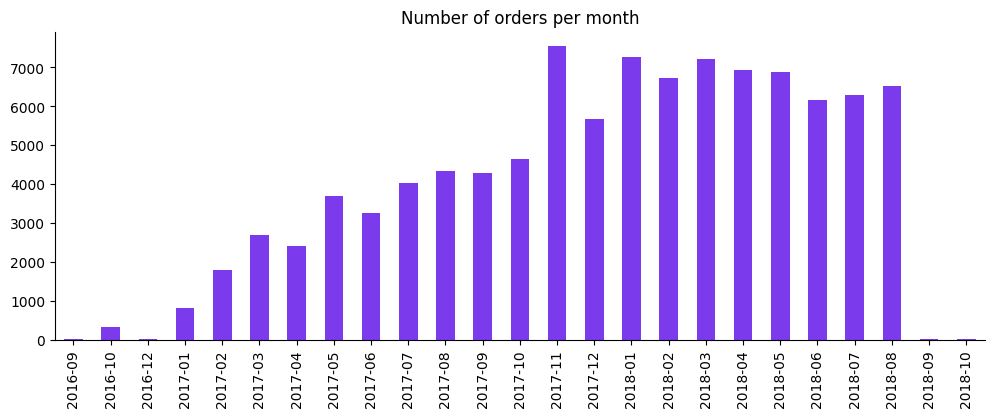

order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2017-01    800
Name: count, dtype: int64

In [8]:
orders_per_month = pd.to_datetime(orders["order_purchase_timestamp"]).dt.strftime("%Y-%m").value_counts().sort_index()

orders_per_month.plot(kind="bar", color=COLOR, figsize=(12, 4), title="Number of orders per month")
plt.xlabel("")
plt.show()
orders_per_month.head(4)

### Customers: `customer_id` vs `customer_unique_id`

In [9]:
print("customer_id values:       ", customers["customer_id"].nunique())
print("customer_unique_id values:", customers["customer_unique_id"].nunique())

customer_id values:        99441
customer_unique_id values: 96096


### What we found

- There are **no duplicate rows**, but **551 orders have more than one review**. We keep the latest one.
- **Missing delivery dates** belong to orders that were never delivered (shipped, canceled and so on). This is expected.
- **Review comments** are often empty, which is normal because writing a comment is optional.
- **610 products have no category**, and category names are in **Portuguese**.
- **97% of orders are delivered.** The rest are canceled, unavailable or still in progress, so we analyse **delivered orders only**.
- **2016 and Sep-Oct 2018 have very few orders**, so we use **Jan 2017 to Aug 2018** (20 full months).
- `customer_id` is different for every order. To count real people we use **`customer_unique_id`**.

## 4. Clean the data

### 4.1 Convert date columns

In [10]:
date_columns = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

orders[date_columns].dtypes

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

### 4.2 Keep delivered orders from Jan 2017 to Aug 2018

In [11]:
print("Orders before cleaning:", len(orders))

orders = orders[orders["order_status"] == "delivered"]
orders = orders.dropna(subset=["order_delivered_customer_date"])
orders = orders[(orders["order_purchase_timestamp"] >= "2017-01-01") &
                (orders["order_purchase_timestamp"] < "2018-09-01")]

print("Orders after cleaning: ", len(orders))

Orders before cleaning: 99441
Orders after cleaning:  96203


### 4.3 Translate product categories to English

In [12]:
products = products.merge(category_names, on="product_category_name", how="left")

# 2 categories are missing from the translation file, so we add them by hand
missing_names = {"pc_gamer": "pc_gamer",
                 "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_processors"}
products["product_category_name_english"] = products["product_category_name_english"].fillna(
    products["product_category_name"].map(missing_names))

# Products with no category get "unknown", then make the names easy to read
products["category"] = products["product_category_name_english"].fillna("unknown")
products["category"] = products["category"].str.replace("_", " ").str.capitalize()

print("Products with no category:", (products["category"] == "Unknown").sum())
products["category"].value_counts().head()

Products with no category: 610


category
Bed bath table     3029
Sports leisure     2867
Furniture decor    2657
Health beauty      2444
Housewares         2335
Name: count, dtype: int64

### 4.4 Keep one review per order (the latest one)

In [13]:
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])
reviews = reviews.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")

print("Orders with more than one review now:", reviews["order_id"].duplicated().sum())

Orders with more than one review now: 0


### 4.5 Fix payments

In [14]:
print("Payments with 0 installments:", (payments["payment_installments"] == 0).sum())
payments.loc[payments["payment_installments"] == 0, "payment_installments"] = 1  # 0 means paid at once

# credit_card -> Credit card
payments["payment_type"] = payments["payment_type"].str.replace("_", " ").str.capitalize()
payments["payment_type"].value_counts()

Payments with 0 installments: 2


payment_type
Credit card    76795
Boleto         19784
Voucher         5775
Debit card      1529
Not defined        3
Name: count, dtype: int64

### 4.6 Create new columns

In [15]:
# Delivery: how many days it took, and whether it arrived after the promised date
orders["delivery_days"] = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.days
orders["promised_days"] = (orders["order_estimated_delivery_date"] - orders["order_purchase_timestamp"]).dt.days
orders["is_late"] = orders["order_delivered_customer_date"].dt.normalize() > orders["order_estimated_delivery_date"]

# Date parts for the time analysis
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.strftime("%Y-%m")
orders["year"] = orders["order_purchase_timestamp"].dt.year
orders["month"] = orders["order_purchase_timestamp"].dt.month
orders["weekday"] = orders["order_purchase_timestamp"].dt.day_name()
orders["hour"] = orders["order_purchase_timestamp"].dt.hour

# Sales value of each product = price + delivery fee (freight)
items["item_value"] = items["price"] + items["freight_value"]

orders[["order_purchase_timestamp", "delivery_days", "promised_days", "is_late", "purchase_month", "weekday"]].head()

,order_purchase_timestamp,delivery_days,promised_days,is_late,purchase_month,weekday
0,2017-10-02 10:56:33,8,15,False,2017-10,Monday
1,2018-07-24 20:41:37,13,19,False,2018-07,Tuesday
2,2018-08-08 08:38:49,9,26,False,2018-08,Wednesday
3,2017-11-18 19:28:06,13,26,False,2017-11,Saturday
4,2018-02-13 21:18:39,2,12,False,2018-02,Tuesday


### 4.7 Merge the tables

We build 3 clean tables:

* `df`: one row per order, with the customer, order value and review score
* `items`: one row per product sold, with its category and the seller's state
* `payments`: one row per payment

In [16]:
# Items: keep only products from our orders, then add category and seller state
items = items[items["order_id"].isin(orders["order_id"])]
items = items.merge(products[["product_id", "category"]], on="product_id", how="left")
items = items.merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")

# Order value = sum of its products
order_value = items.groupby("order_id")["item_value"].sum().rename("order_value").reset_index()

# Orders: add customer, order value and review score
df = orders.merge(customers, on="customer_id", how="left")
df = df.merge(order_value, on="order_id", how="left")
df = df.merge(reviews[["order_id", "review_score"]], on="order_id", how="left")

payments = payments[payments["order_id"].isin(df["order_id"])]

# Checks
print("Orders:", len(df), "| unique order_id:", df["order_id"].is_unique)
print("Orders with no value:", df["order_value"].isna().sum())
print("Orders with no review:", df["review_score"].isna().sum())
print("Products sold:", len(items), "| payments:", len(payments))

Orders: 96203 | unique order_id: True
Orders with no value: 0
Orders with no review: 643
Products sold: 109872 | payments: 100465


## 5. Analysis

### Q1. How is the business doing overall?

In [17]:
total_revenue = df["order_value"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_unique_id"].nunique()
avg_order_value = total_revenue / total_orders
avg_review = df["review_score"].mean()
late_rate = df["is_late"].mean()

print(f"Total revenue:       R$ {total_revenue:,.0f}")
print(f"Total orders:        {total_orders:,}")
print(f"Total customers:     {total_customers:,}")
print(f"Average order value: R$ {avg_order_value:,.2f}")
print(f"Average review:      {avg_review:.2f} / 5")
print(f"Late deliveries:     {late_rate:.1%}")

Total revenue:       R$ 15,371,741
Total orders:        96,203
Total customers:     93,096
Average order value: R$ 159.78
Average review:      4.16 / 5
Late deliveries:     6.8%


**Insight:** From Jan 2017 to Aug 2018, Olist made **R\$ 15.37M** from **96,203 delivered orders** and **93,096 customers**. An average order is worth about **R\$ 160**. Customers are mostly happy (**4.16 / 5**), and only **6.8%** of orders arrive late.

### Q2. How do sales change over time?

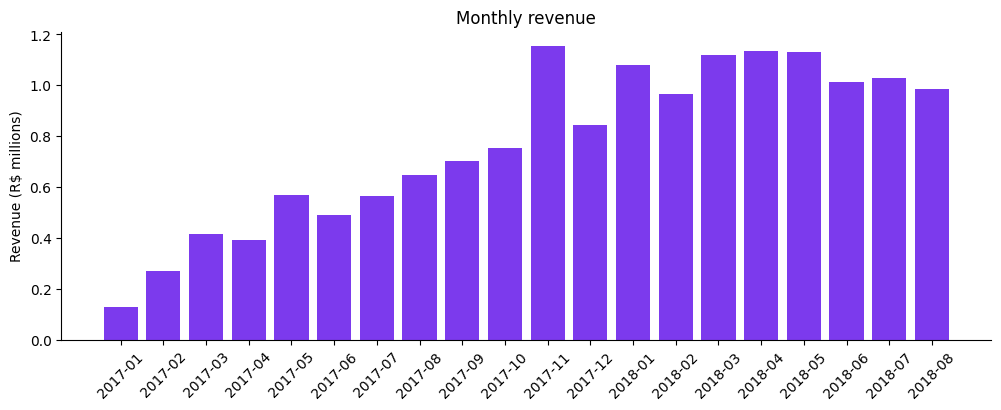

Best month: 2017-11 with R$ 1,153,229 from 7,288 orders


In [18]:
monthly = df.groupby("purchase_month").agg(revenue=("order_value", "sum"),
                                           orders=("order_id", "count")).reset_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly["purchase_month"], monthly["revenue"] / 1_000_000, color=COLOR)
ax.set_title("Monthly revenue")
ax.set_ylabel("Revenue (R$ millions)")
plt.xticks(rotation=45)
plt.show()

best = monthly.loc[monthly["revenue"].idxmax()]
print(f"Best month: {best['purchase_month']} with R$ {best['revenue']:,.0f} from {best['orders']:,} orders")

In [19]:
# Compare the same months (Jan-Aug) of 2017 and 2018
jan_aug = df[df["month"] <= 8].groupby("year")["order_value"].sum()
growth = jan_aug[2018] / jan_aug[2017] - 1
print(f"Jan-Aug 2017: R$ {jan_aug[2017]:,.0f}")
print(f"Jan-Aug 2018: R$ {jan_aug[2018]:,.0f}")
print(f"Growth: {growth:.0%}")

# Is 2018 still growing? Compare the first and last 3 months of 2018
m2018 = monthly[monthly["purchase_month"].str.startswith("2018")]["revenue"]
print(f"2018 last 3 months vs first 3 months: {m2018.tail(3).mean() / m2018.head(3).mean() - 1:+.0%}")

Jan-Aug 2017: R$ 3,472,704
Jan-Aug 2018: R$ 8,450,535
Growth: 143%
2018 last 3 months vs first 3 months: -4%


In [20]:
# Best single day
daily = df.groupby(df["order_purchase_timestamp"].dt.date)["order_value"].agg(["sum", "count"])
print("Best day:", daily["sum"].idxmax(), f"R$ {daily['sum'].max():,.0f} from {daily.loc[daily['sum'].idxmax(), 'count']:,} orders")
print(f"Average day: R$ {daily['sum'].mean():,.0f}")

Best day: 2017-11-24 R$ 175,178 from 1,147 orders
Average day: R$ 25,534


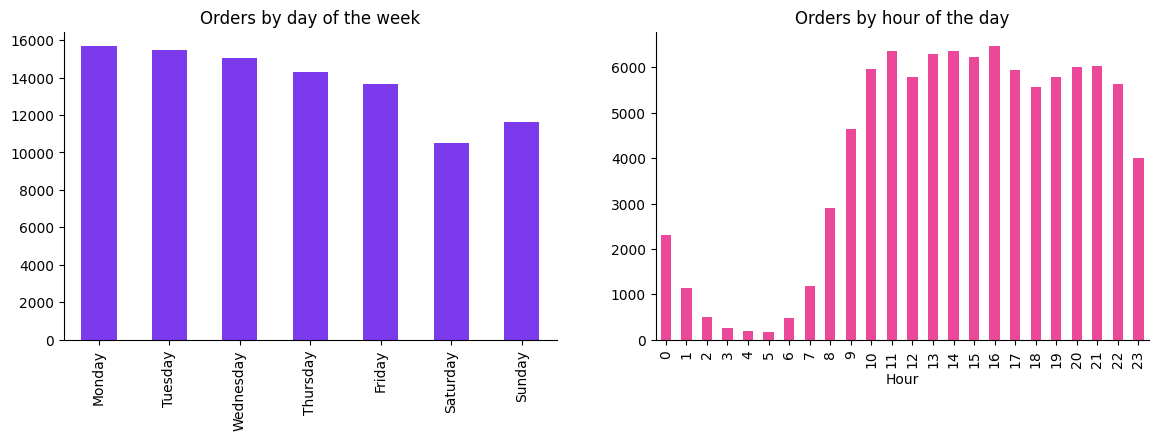

Busiest day: Monday | quietest day: Saturday
Orders between 10:00 and 22:00: 76%


In [21]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = df["weekday"].value_counts().reindex(weekday_order)
by_hour = df["hour"].value_counts().sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
by_weekday.plot(kind="bar", color=COLOR, ax=ax1, title="Orders by day of the week")
by_hour.plot(kind="bar", color=COLOR2, ax=ax2, title="Orders by hour of the day")
ax1.set_xlabel("")
ax2.set_xlabel("Hour")
plt.show()

print("Busiest day:", by_weekday.idxmax(), "| quietest day:", by_weekday.idxmin())
print(f"Orders between 10:00 and 22:00: {by_hour.loc[10:21].sum() / by_hour.sum():.0%}")

**Insight:**
- Revenue grew **143%**: Jan-Aug 2018 made R\$ 8.45M, compared with R\$ 3.47M in Jan-Aug 2017.
- But inside 2018, monthly revenue was **flat** (the last 3 months were 4% lower than the first 3). Growth is slowing down.
- The best month was **November 2017** (R\$ 1.15M) because of **Black Friday (24 Nov 2017)**. That one day made R\$ 175K from 1,147 orders, about **7 times** a normal day.
- Customers order most on **Monday** and least on **Saturday**, and **76%** of orders are placed between 10:00 and 22:00.

### Q3. Which product categories sell the most?

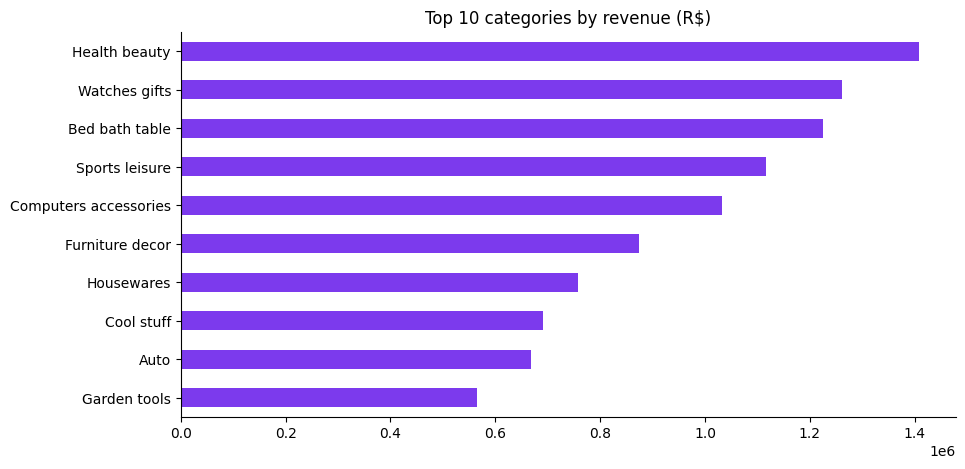

Number of categories: 74
Top 10 categories = 62% of revenue


,revenue,orders,share_%
category,,,
Health beauty,"1,407,759.78",8610,9.16
Watches gifts,"1,261,223.27",5489,8.20
Bed bath table,"1,224,602.68",9267,7.97
Sports leisure,"1,115,572.15",7512,7.26
Computers accessories,"1,031,741.81",6517,6.71
Furniture decor,"873,430.57",6258,5.68
Housewares,"756,849.71",5734,4.92
Cool stuff,"690,444.01",3552,4.49
Auto,"667,968.65",3801,4.35


In [22]:
category_sales = items.groupby("category").agg(revenue=("item_value", "sum"),
                                               orders=("order_id", "nunique")).sort_values("revenue", ascending=False)
category_sales["share_%"] = category_sales["revenue"] / category_sales["revenue"].sum() * 100

category_sales.head(10)["revenue"].sort_values().plot(kind="barh", color=COLOR, figsize=(10, 5),
                                                       title="Top 10 categories by revenue (R$)")
plt.ylabel("")
plt.show()

print("Number of categories:", len(category_sales))
print(f"Top 10 categories = {category_sales.head(10)['share_%'].sum():.0f}% of revenue")
category_sales.head(10)

In [23]:
# Most orders is not always the most money
category_sales.sort_values("orders", ascending=False).head(5)[["orders", "revenue"]]

,orders,revenue
category,,
Bed bath table,9267,"1,224,602.68"
Health beauty,8610,"1,407,759.78"
Sports leisure,7512,"1,115,572.15"
Computers accessories,6517,"1,031,741.81"
Furniture decor,6258,"873,430.57"


In [24]:
# Do a few sellers make most of the money?
seller_sales = items.groupby("seller_id")["item_value"].sum().sort_values(ascending=False)
top_20_percent = int(len(seller_sales) * 0.2)
print("Sellers:", len(seller_sales))
print(f"Top 20% of sellers make {seller_sales.head(top_20_percent).sum() / seller_sales.sum():.0%} of revenue")

Sellers: 2945
Top 20% of sellers make 82% of revenue


**Insight:**
- **Health beauty** makes the most money (R\$ 1.41M, 9% of revenue), followed by Watches gifts, Bed bath table and Sports leisure.
- **Bed bath table** has the most orders (9,267), but its products are cheaper, so it is third by revenue.
- The **top 10 of 74 categories make 62%** of revenue.
- Sellers are concentrated too: the **top 20% of sellers make 82%** of revenue.

### Q4. Where are the customers, and do they come back?

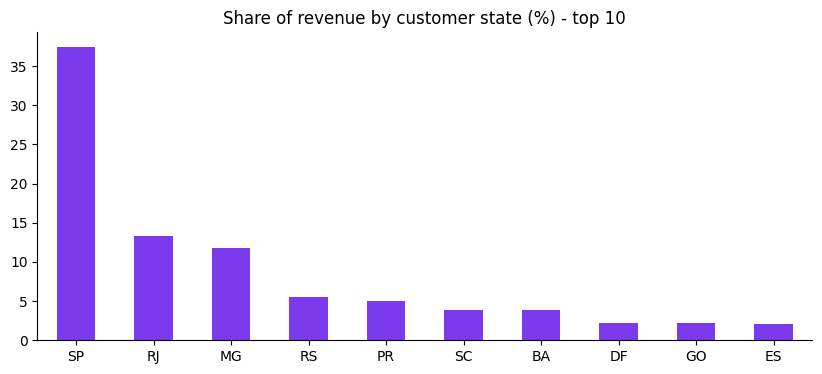

Top 3 states = 63% of revenue


,revenue,customers,avg_order_value,share_%
customer_state,,,,
SP,"5,754,814.84",39058,142.45,37.44
RJ,"2,046,357.64",11879,166.24,13.31
MG,"1,813,954.27",10969,160.26,11.80
RS,"858,380.68",5150,161.14,5.58
PR,"779,214.08",4750,158.93,5.07
SC,"592,627.06",3441,167.55,3.86
BA,"590,816.80",3155,181.62,3.84
DF,"344,923.24",2013,166.31,2.24
GO,"333,156.23",1889,170.85,2.17


In [25]:
state_sales = df.groupby("customer_state").agg(revenue=("order_value", "sum"),
                                               customers=("customer_unique_id", "nunique"),
                                               avg_order_value=("order_value", "mean")).sort_values("revenue", ascending=False)
state_sales["share_%"] = state_sales["revenue"] / state_sales["revenue"].sum() * 100

state_sales.head(10)["share_%"].plot(kind="bar", color=COLOR, title="Share of revenue by customer state (%) - top 10")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

print(f"Top 3 states = {state_sales.head(3)['share_%'].sum():.0f}% of revenue")
state_sales.head(10)

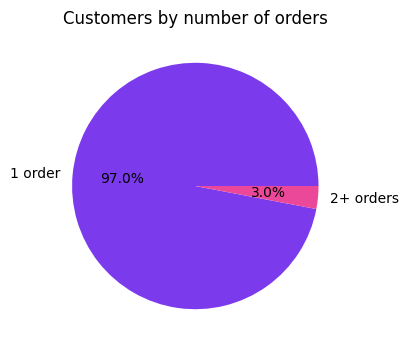

Customers who bought more than once: 3.0%


In [26]:
orders_per_customer = df.groupby("customer_unique_id")["order_id"].count()
repeat_rate = (orders_per_customer > 1).mean()

counts = pd.Series({"1 order": (orders_per_customer == 1).sum(), "2+ orders": (orders_per_customer > 1).sum()})
counts.plot(kind="pie", autopct="%.1f%%", colors=[COLOR, COLOR2], ylabel="", title="Customers by number of orders")
plt.show()
print(f"Customers who bought more than once: {repeat_rate:.1%}")

**Insight:**
- **São Paulo (SP)** alone makes **37%** of revenue. With Rio de Janeiro (RJ) and Minas Gerais (MG), the top 3 states make **63%**.
- Customers in SP spend the least per order (R\$ 142), while states further away spend more, for example Bahia (R\$ 182).
- Only **3.0% of customers ordered more than once**. Almost every order comes from a new customer.

### Q5. How fast is delivery?

Average delivery time: 12.1 days
Median delivery time:  10 days
Average promised time: 23.3 days
Late deliveries:       6.8%


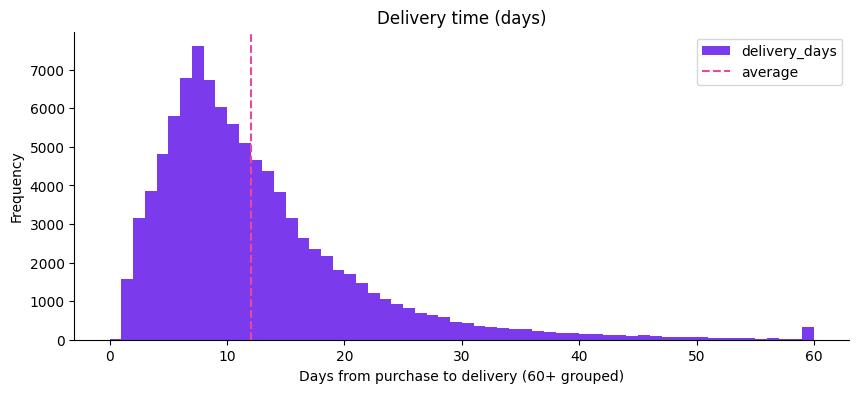

In [27]:
print(f"Average delivery time: {df['delivery_days'].mean():.1f} days")
print(f"Median delivery time:  {df['delivery_days'].median():.0f} days")
print(f"Average promised time: {df['promised_days'].mean():.1f} days")
print(f"Late deliveries:       {late_rate:.1%}")

df["delivery_days"].clip(upper=60).plot(kind="hist", bins=60, color=COLOR, title="Delivery time (days)")
plt.axvline(df["delivery_days"].mean(), color=COLOR2, linestyle="--", label="average")
plt.xlabel("Days from purchase to delivery (60+ grouped)")
plt.legend()
plt.show()

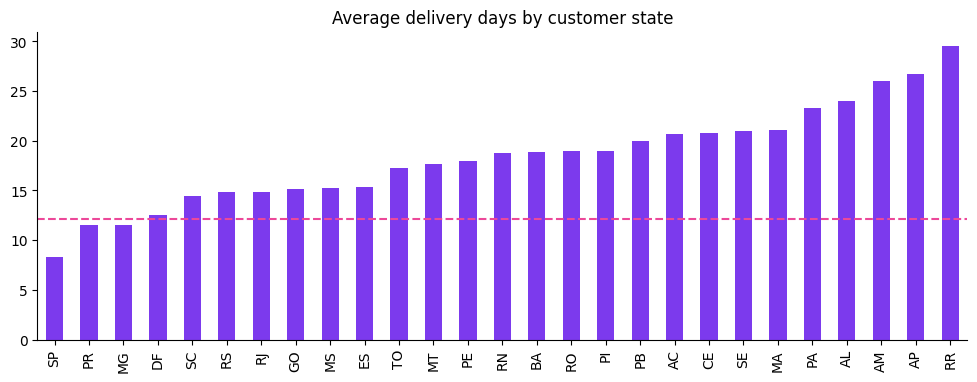

Products sent by sellers in Sao Paulo (SP): 71%


,avg_delivery_days,late_rate,orders
customer_state,,,
RR,29.50,0.12,40
AP,26.73,0.03,67
AM,25.99,0.03,145
AL,24.02,0.21,396
PA,23.30,0.11,942


In [28]:
state_delivery = df.groupby("customer_state").agg(avg_delivery_days=("delivery_days", "mean"),
                                                  late_rate=("is_late", "mean"),
                                                  orders=("order_id", "count")).sort_values("avg_delivery_days")

state_delivery["avg_delivery_days"].plot(kind="bar", color=COLOR, figsize=(12, 4),
                                         title="Average delivery days by customer state")
plt.axhline(df["delivery_days"].mean(), color=COLOR2, linestyle="--")
plt.xlabel("")
plt.show()

print(f"Products sent by sellers in Sao Paulo (SP): {(items['seller_state'] == 'SP').mean():.0%}")
state_delivery.sort_values("avg_delivery_days", ascending=False).head(5)

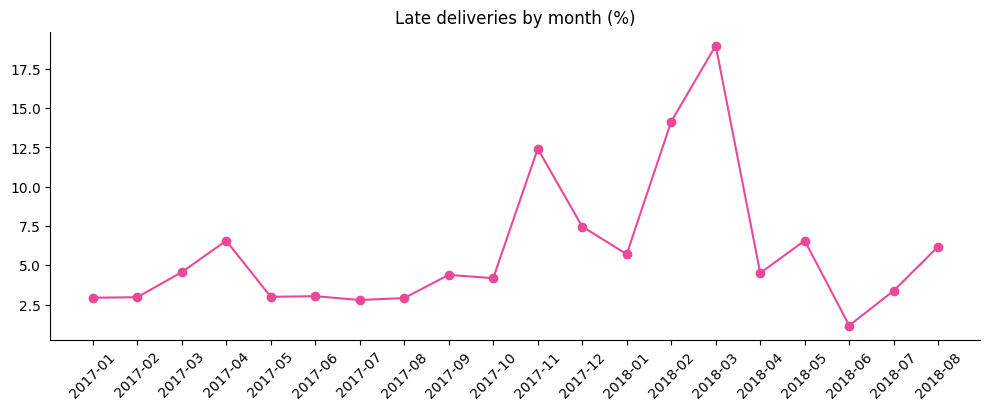

purchase_month
2018-03   18.96
2018-02   14.13
2017-11   12.40
Name: is_late, dtype: float64

In [29]:
monthly_late = df.groupby("purchase_month")["is_late"].mean() * 100
monthly_late.plot(color=COLOR2, marker="o", figsize=(12, 4), title="Late deliveries by month (%)")
plt.xticks(range(len(monthly_late)), monthly_late.index, rotation=45)
plt.xlabel("")
plt.show()
monthly_late.sort_values(ascending=False).head(3)

**Insight:**
- Delivery takes **12 days** on average (median 10 days).
- Olist promises **23 days**, so most orders arrive about **11 days earlier than promised**. That is why only **6.8%** are late.
- **Distance matters:** customers in Amazonas (26 days), Alagoas (24) and Pará (23) wait about twice the average, because **71%** of products are sent from São Paulo.
- Late deliveries jumped in **Feb-Mar 2018** (up to 19%) and in **Nov 2017** after Black Friday.

### Q6. Does late delivery affect review scores?

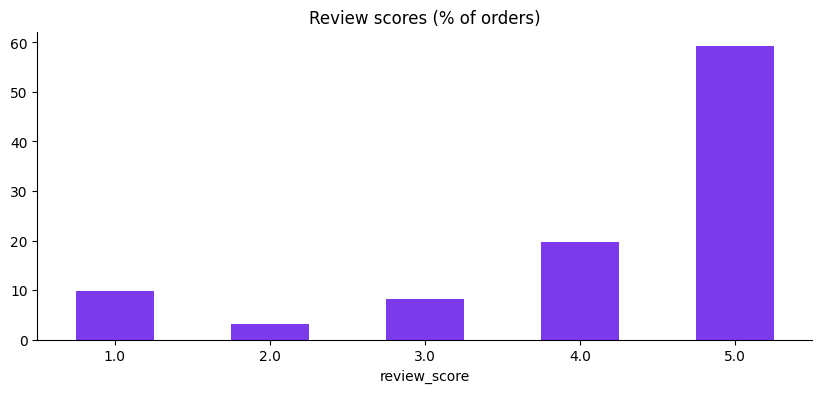

5-star reviews:   59%
1-2 star reviews: 13%


In [30]:
df["review_score"].value_counts(normalize=True).sort_index().mul(100).plot(
    kind="bar", color=COLOR, title="Review scores (% of orders)")
plt.xticks(rotation=0)
plt.show()
print(f"5-star reviews:   {(df['review_score'] == 5).mean():.0%}")
print(f"1-2 star reviews: {(df['review_score'] <= 2).mean():.0%}")

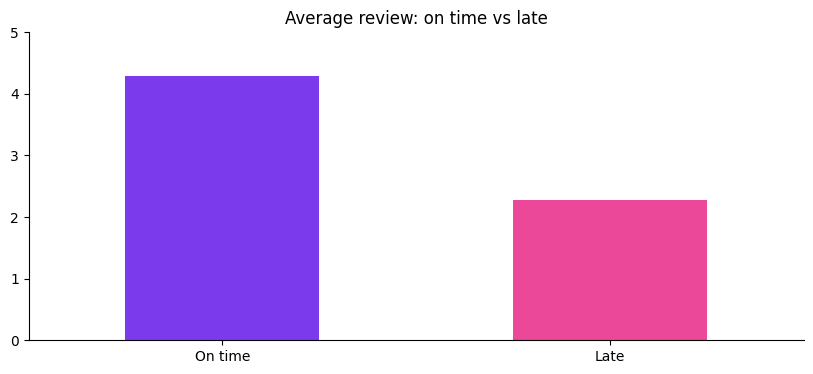

,avg_review,bad_reviews_pct,orders
delivery_status,,,
On time,4.29,9.20,89672
Late,2.27,60.96,6531


In [31]:
df["delivery_status"] = df["is_late"].map({False: "On time", True: "Late"})
late_vs_on_time = df.groupby("delivery_status").agg(
    avg_review=("review_score", "mean"),
    bad_reviews_pct=("review_score", lambda s: (s <= 2).mean() * 100),
    orders=("order_id", "count")).reindex(["On time", "Late"])

late_vs_on_time["avg_review"].plot(kind="bar", color=[COLOR, COLOR2], title="Average review: on time vs late")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.xlabel("")
plt.show()
late_vs_on_time

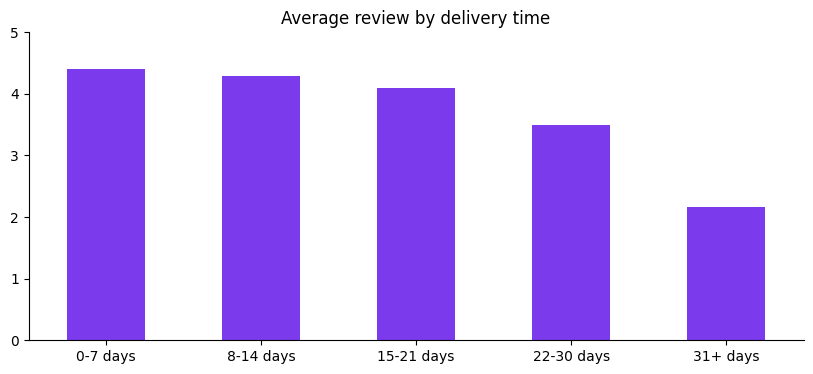

delivery_group
0-7 days     4.41
8-14 days    4.29
15-21 days   4.10
22-30 days   3.49
31+ days     2.16
Name: review_score, dtype: float64

In [32]:
# Longer delivery -> lower review?
df["delivery_group"] = pd.cut(df["delivery_days"], bins=[-1, 7, 14, 21, 30, 1000],
                              labels=["0-7 days", "8-14 days", "15-21 days", "22-30 days", "31+ days"])
review_by_time = df.groupby("delivery_group", observed=True)["review_score"].mean()

review_by_time.plot(kind="bar", color=COLOR, title="Average review by delivery time")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.xlabel("")
plt.show()
review_by_time

In [33]:
# Categories with the lowest reviews (only categories with 500+ orders)
items_reviews = items.merge(df[["order_id", "review_score"]], on="order_id")
category_reviews = items_reviews.groupby("category").agg(avg_review=("review_score", "mean"),
                                                         orders=("order_id", "nunique"))
category_reviews[category_reviews["orders"] >= 500].sort_values("avg_review").head(5)

,avg_review,orders
category,,
Office furniture,3.52,1248
Bed bath table,3.92,9267
Unknown,3.94,1390
Furniture decor,3.96,6258
Computers accessories,3.99,6517


**Insight: yes, a lot.**
- Late orders get **2.27 stars** on average, compared with **4.29** for on-time orders.
- **61%** of late orders get 1-2 stars, but only **9%** of on-time orders do.
- The longer the wait, the lower the score: **4.41** for 0-7 days, down to **2.16** for 31+ days.
- **Office furniture** has the lowest score (3.52). **Bed bath table**, a top seller, is also below average (3.92).

### Q7. How do customers pay?

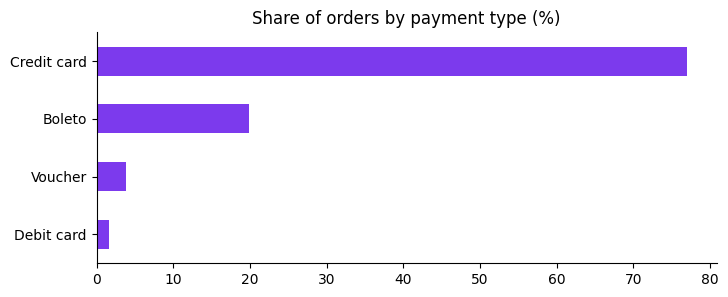

payment_type
Credit card   77.00
Boleto        19.90
Voucher        3.80
Debit card     1.50
Name: order_id, dtype: float64

In [34]:
payment_share = payments.groupby("payment_type")["order_id"].nunique().sort_values(ascending=False)
payment_share_pct = payment_share / payments["order_id"].nunique() * 100

payment_share_pct.sort_values().plot(kind="barh", color=COLOR, figsize=(8, 3),
                                     title="Share of orders by payment type (%)")
plt.ylabel("")
plt.show()

# A few orders use 2 payment types (for example card + voucher), so the shares add up to a bit over 100%
payment_share_pct.round(1)

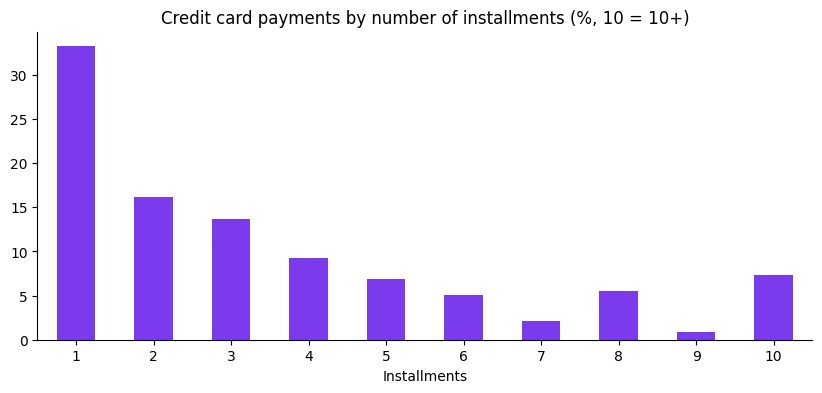

Card payments paid in 2+ installments: 67%
payment_installments
1 installment      96.00
2+ installments   195.00


In [35]:
cards = payments[payments["payment_type"] == "Credit card"]
installments = cards["payment_installments"].clip(upper=10).value_counts(normalize=True).sort_index() * 100

installments.plot(kind="bar", color=COLOR, title="Credit card payments by number of installments (%, 10 = 10+)")
plt.xticks(rotation=0)
plt.xlabel("Installments")
plt.show()

print(f"Card payments paid in 2+ installments: {(cards['payment_installments'] > 1).mean():.0%}")
print(cards.groupby(cards["payment_installments"] > 1)["payment_value"].mean()
      .rename({False: "1 installment", True: "2+ installments"}).round(0).to_string())

**Insight:**
- **Credit card** is used in **77%** of orders, and **boleto** (a Brazilian bank slip) in **20%**. Voucher (4%) and debit card (1.5%) are small.
- **67%** of card payments are split into **installments**. Payments with installments are about twice as big (R\$ 195 vs R\$ 96), so installments help sell more expensive products.

## 6. Business insights and recommendations

| Question | Answer |
| --- | --- |
| How is the business doing? | R\$ 15.37M from 96,203 orders, about R\$ 160 per order |
| Are sales growing? | +143% vs 2017, but flat during 2018 |
| Best category? | Health beauty. Top 10 categories = 62% of revenue |
| Where are customers? | Mostly São Paulo. Top 3 states = 63%. Only 3% buy again |
| Is delivery fast? | 12 days on average. Far states wait 23-26 days |
| Does delivery affect reviews? | Yes: 2.27 stars late vs 4.29 on time |
| How do customers pay? | Credit card (77%), often in installments |

**Recommendations**

1. **Improve delivery first.** It has the biggest effect on reviews. Set a shipping time limit for sellers, and tell customers early when an order will be late.
2. **Get closer to far-away customers.** Find sellers or warehouses in the North and Northeast, where customers wait the longest.
3. **Bring customers back.** Only 3% buy again. Try follow-up emails, a discount on the second order and a loyalty programme.
4. **Prepare for Black Friday.** More stock, more sellers and more delivery capacity, so the busiest day does not cause late orders.
5. **Protect the top categories and sellers.** Keep the top 10 categories in stock and support the top sellers, because a few of them make most of the revenue.
6. **Keep installments and boleto.** They help customers buy expensive products and customers without a credit card.

**Limitations:** the data covers only 2017-2018, has no cost or marketing data (so no profit analysis), and only customers who chose to leave a review are included in the review numbers.

## 7. Save the clean data for the dashboard

The Streamlit dashboard (`app.py`) reads these files, so it shows the same numbers as this notebook.

In [36]:
os.makedirs("data", exist_ok=True)

df[["order_id", "customer_unique_id", "customer_state", "order_purchase_timestamp",
    "delivery_days", "promised_days", "is_late", "review_score", "order_value"]].to_csv("data/orders_clean.csv", index=False)
items[["order_id", "category", "seller_state", "price", "freight_value", "item_value"]].to_csv("data/items_clean.csv", index=False)
payments[["order_id", "payment_type", "payment_installments", "payment_value"]].to_csv("data/payments_clean.csv", index=False)

for file in sorted(os.listdir("data")):
    print(f"data/{file:20} {os.path.getsize('data/' + file) / 1_000_000:.1f} MB")

data/items_clean.csv      7.8 MB
data/orders_clean.csv     11.0 MB
data/payments_clean.csv   5.3 MB
